In [1]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import gymnasium as gym
import keras.backend as K
import matplotlib.pyplot as plt

from tensorflow.keras.layers import Dense
from tensorflow.keras.losses import Huber
from tensorflow.keras.regularizers import l2
from tensorflow.keras.models import Sequential, load_model

I0000 00:00:1792431251.903492  717278 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792431251.903988  717278 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792431251.991618  717278 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792431253.578935  717278 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [2]:
huber = Huber(delta=1.0) # Quadratic loss below or equal to 1.0, Linear loss above 1.0, to reduce large updates.

@tf.keras.utils.register_keras_serializable()
def masked_huber_loss(y_true, y_pred):
    y_true = tf.cast(y_true, y_pred.dtype)       # Make both inputs the same number type
    mask = tf.logical_not(tf.math.is_nan(y_true))

    taken_true = tf.boolean_mask(y_true, mask)   # Keep the target value for the taken action
    taken_pred = tf.boolean_mask(y_pred, mask)   # Keep the networks guess for that action
    return huber(taken_true, taken_pred)

In [3]:
env = gym.make("LunarLander-v3")

# For visual, use render_mode="human"
# env = gym.make("LunarLander-v3", render_mode="human")

In [4]:
n_inputs = int(env.observation_space.shape[0] + 1)   # 8 state values from the environment + 1 for how far into the episode we are.
n_actions = int(env.action_space.n)                  # 4 possible actions 

def create_model(learning_rate, regularization_factor, layer_sizes=(64, 64, 64)):
    model = Sequential()
    model.add(tf.keras.Input(shape=(n_inputs,)))  # Input: one state with 9 numbers

    for size in layer_sizes:
        model.add(Dense(size, activation="relu", kernel_regularizer=l2(regularization_factor))) # L2 keeps the weights small

    model.add(Dense(n_actions, activation="linear", kernel_regularizer=l2(regularization_factor))) # linear since Q-values can be any number (also negative)

    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), # Adam is my choice of optimizer. Maybe try RMSProp?
                loss=masked_huber_loss)
    return model

In [5]:
class EpsilonGreedy:
    def __init__(self, epsilon=1.0, epsilon_min=0.01, epsilon_decay=0.995):
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay

    def select_action(self, q_values, n_actions=4):
        if np.random.random() < self.epsilon:
            return np.random.randint(n_actions)
        return np.argmax(q_values)

    def decay(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

In [6]:
class StateTransition():
  def __init__(self, old_state, action, reward, new_state, done):
    self.old_state = old_state
    self.action = action
    self.reward = reward
    self.new_state = new_state
    self.done = done


# Replay buffer class
class ReplayBuffer():
  current_index = 0

  def __init__(self, size = 10000):
    self.size = size
    self.transitions = []

  def add(self, transition):
    if len(self.transitions) < self.size:
      self.transitions.append(transition)
    else:
      self.transitions[self.current_index] = transition
      self.__increment_current_index()

  def length(self):
    return len(self.transitions)

  def get_batch(self, batch_size):
    return random.sample(self.transitions, batch_size)

  def __increment_current_index(self):
    self.current_index += 1
    if self.current_index >= self.size - 1:
      self.current_index = 0

In [7]:
def get_q_values(model, state):
  input = state[np.newaxis, ...]
  return model(input, training=False).numpy()[0]

def get_multiple_q_values(model, states):
  return model(states, training=False).numpy()

def select_best_action(q_values):
  return np.argmax(q_values)

def calculate_target_values(model, target_model, state_transitions, discount_factor, n_actions=4):
  states = []
  new_states = []
  for transition in state_transitions:
    states.append(transition.old_state)
    new_states.append(transition.new_state)

  new_states = np.array(new_states)
  q_values_new_state = get_multiple_q_values(model, new_states)
  q_values_new_state_target_model = get_multiple_q_values(target_model, new_states)

  targets = []
  for index, state_transition in enumerate(state_transitions):
    best_action = select_best_action(q_values_new_state[index])
    best_action_next_state_q_value = q_values_new_state_target_model[index][best_action]

    if state_transition.done:
      target_value = state_transition.reward
    else:
      target_value = state_transition.reward + discount_factor * best_action_next_state_q_value

    target_vector = [np.nan] * n_actions
    target_vector[state_transition.action] = target_value
    targets.append(target_vector)

  return np.array(targets, dtype=np.float32)

In [8]:
def copy_model(model):
  new_model = tf.keras.models.clone_model(model)
  new_model.set_weights(model.get_weights())
  return new_model

In [9]:
replay_buffer_size = 200000
training_batch_size = 128
training_start = 256

max_episodes = 10000
# max_episodes = 10

max_step = 1000
target_network_replace_frequency_steps = 1000
discount_factor = 0.99
train_every_x_steps = 4
learning_rate = 0.001
regularization_factor = 0.000001
solved_score = 200

replay_buffer = ReplayBuffer(replay_buffer_size)
step_count = 0

def train_model(model, states, targets):
    model.train_on_batch(states, targets)

In [10]:
# Main loop
replay_buffer = ReplayBuffer(replay_buffer_size)
epsilon_greedy = EpsilonGreedy()
model = create_model(learning_rate, regularization_factor)
target_model = copy_model(model)
step_count = 0
episode_rewards = []

fuel_consumptions = []

for episode in range (max_episodes):
    episode_reward = 0
    state, _ = env.reset()
    fraction_finished = 0.0
    state = np.append(state, fraction_finished)
    first_q_values = get_q_values(model, state)

    # Fuel consumption 
    fuel_consumption = 0.0

    for step in range (1, max_step + 1):
        step_count += 1
        q_values = get_q_values(model, state)
        action = epsilon_greedy.select_action(q_values)
        new_state, reward, done, info, _ = env.step(action)
        fraction_finished = (step + 1) / max_step
        new_state = np.append(new_state, fraction_finished)
        episode_reward += reward

        # Update fuel consumption until landed, or crashed.
        # Reward for fuel consumption is (-0.03 or -0.3)
        if reward < 0 or reward == (-100):
            fuel_consumption += reward * (-1)

        # if step == max_step:
            # print("Not landed yet...")

        state_transition = StateTransition(state, action, reward, new_state, done)
        replay_buffer.add(state_transition)
        state = new_state

        if step_count % target_network_replace_frequency_steps == 0:
            # print("Updating target model")
            target_model = copy_model(model)

        if replay_buffer.length() >= training_start and step_count % train_every_x_steps == 0:
            batch = replay_buffer.get_batch(batch_size=training_batch_size)
            targets = calculate_target_values(model, target_model, batch, discount_factor)
            states = np.array([state_transition.old_state for state_transition in batch])
            train_model(model, states, targets)

        if done or info:
            break

    epsilon_greedy.decay()
    episode_rewards.append(episode_reward)
    average_100 = np.mean(episode_rewards[-100:])

    # Update fuel consumption
    fuel_consumptions.append(fuel_consumption)

    if episode % 10 == 0:
        print(f"Episode {episode:5d} | reward {episode_reward:8.1f} | avg100 {average_100:8.1f} | epsilon {epsilon_greedy.epsilon:.3f} | steps {step_count}")

    if len(episode_rewards) >= 100 and average_100 >= solved_score:
        print(f"Solved after {episode} episodes! avg100 = {average_100:.1f}")
        model.save("lunar_lander_dqn.keras")
        break

E0000 00:00:1792431255.418644  717278 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1792431255.437038  717278 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Episode     0 | reward   -286.2 | avg100   -286.2 | epsilon 0.995 | steps 96
Episode    10 | reward    -88.6 | avg100   -188.9 | epsilon 0.946 | steps 1123
Episode    20 | reward   -305.7 | avg100   -168.5 | epsilon 0.900 | steps 1973
Episode    30 | reward    -71.2 | avg100   -157.0 | epsilon 0.856 | steps 2851
Episode    40 | reward    -69.2 | avg100   -148.5 | epsilon 0.814 | steps 3833
Episode    50 | reward   -125.6 | avg100   -141.9 | epsilon 0.774 | steps 4881
Episode    60 | reward    -88.4 | avg100   -137.8 | epsilon 0.737 | steps 5944
Episode    70 | reward    -99.7 | avg100   -133.9 | epsilon 0.701 | steps 7122
Episode    80 | reward   -101.7 | avg100   -127.3 | epsilon 0.666 | steps 8315
Episode    90 | reward    -20.6 | avg100   -121.4 | epsilon 0.634 | steps 9554
Episode   100 | reward   -100.1 | avg100   -113.1 | epsilon 0.603 | steps 10748
Episode   110 | reward   -160.5 | avg100   -101.1 | epsilon 0.573 | steps 12286
Episode   120 | reward    -14.9 | avg100    -89.2 | 

## Episode Plot

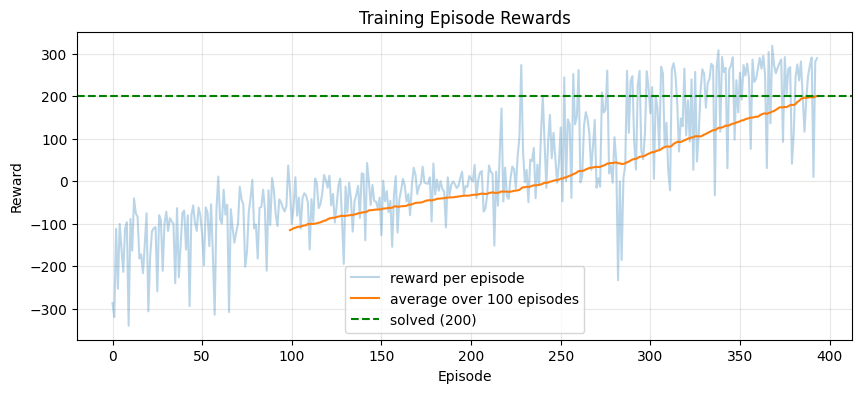

In [11]:
# Display average 100 reward
rewards = pd.Series(episode_rewards)
plt.figure(figsize=(10, 4))
plt.plot(rewards, alpha=0.3, label="reward per episode")
plt.plot(rewards.rolling(100).mean(), label="average over 100 episodes")
plt.axhline(200, color="green", linestyle="--", label="solved (200)")
plt.title("Training Episode Rewards")
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


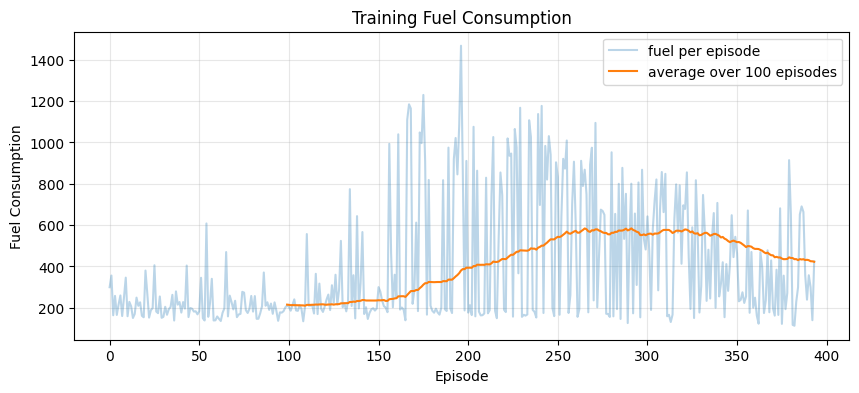

In [12]:
import pandas as pd

fuel = pd.Series(fuel_consumptions)
plt.figure(figsize=(10, 4))
plt.plot(fuel, alpha=0.3, label="fuel per episode")
plt.plot(fuel.rolling(100).mean(), label="average over 100 episodes")
plt.title("Training Fuel Consumption")
plt.xlabel("Episode")
plt.ylabel("Fuel Consumption")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [13]:
# Close gymnasium environment
env.close()

## Model Testing

In [14]:
import gymnasium as gym
import numpy as np
from tensorflow import keras

model = keras.models.load_model("lunar_lander_dqn.keras")
env = gym.make("LunarLander-v3")

episodes = 50
max_step = 1000
landed = 0
landed = 0
landed_within_goal = 0

# Statistical measures
fuel_consumptions = []
episode_rewards = []

for episode in range(episodes):
    state, _ = env.reset()
    state = np.append(state, 0.0)
    fuel_consumption = 0.0
    episode_reward = 0.0

    for step in range(1, max_step + 1):

        q_values = model.predict(
            np.expand_dims(state, axis=0),
            verbose=0)

        action = np.argmax(q_values[0])
        new_state, reward, terminated, truncated, _ = env.step(action)
        fraction_finished = (step + 1) / max_step
        state = np.append(new_state, fraction_finished)
        episode_reward += reward

        # Update fuel consumption until landed, or crashed.
        if reward < 0 or reward == (-100):
            fuel_consumption += reward * (-1)

        if terminated or truncated:
            break

    if episode_reward > 0:
        landed += 1
    if episode_reward >= 200:
        landed_within_goal += 1

    print(f"Episode {episode + 1}: reward = {episode_reward:.1f}")
    print(f"Fuel consumption during episode: {fuel_consumption}")
    fuel_consumptions.append(fuel_consumption)
    episode_rewards.append(episode_reward)

env.close()

Episode 1: reward = 298.3
Fuel consumption during episode: 65.98454457335177
Episode 2: reward = 208.9
Fuel consumption during episode: 288.486043537513
Episode 3: reward = 267.0
Fuel consumption during episode: 97.99727359435053
Episode 4: reward = 240.4
Fuel consumption during episode: 203.6176172951234
Episode 5: reward = 246.7
Fuel consumption during episode: 143.26151445145462
Episode 6: reward = 65.6
Fuel consumption during episode: 556.3368948467527
Episode 7: reward = 286.2
Fuel consumption during episode: 121.416061372461
Episode 8: reward = 267.1
Fuel consumption during episode: 154.46806351314598
Episode 9: reward = 241.8
Fuel consumption during episode: 142.34176979369366
Episode 10: reward = 257.0
Fuel consumption during episode: 146.79163951667937
Episode 11: reward = 198.4
Fuel consumption during episode: 349.34044921095216
Episode 12: reward = 251.2
Fuel consumption during episode: 140.89472940388922
Episode 13: reward = 291.8
Fuel consumption during episode: 122.569438

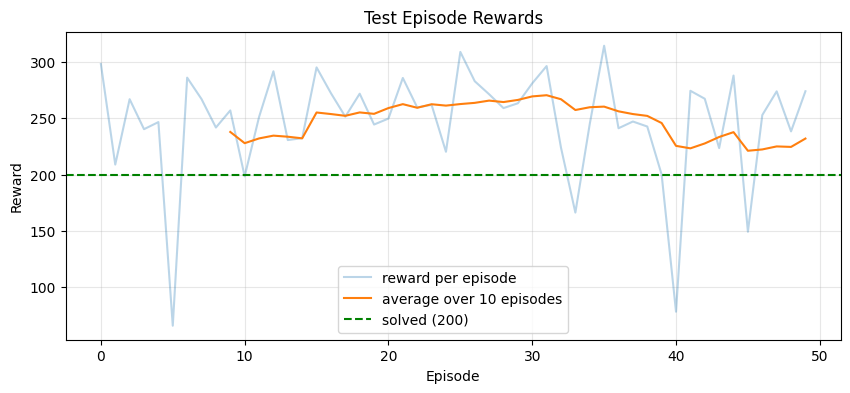

In [15]:
import pandas as pd

rewards = pd.Series(episode_rewards)
plt.figure(figsize=(10, 4))
plt.plot(rewards, alpha=0.3, label="reward per episode")
plt.plot(rewards.rolling(10).mean(), label="average over 10 episodes")
plt.axhline(200, color="green", linestyle="--", label="solved (200)")
plt.title("Test Episode Rewards")
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



Landed: 50/50
Landed within goal: 44/50
Success rate: 100.0%
Success rate (landed within goal): 88.0%


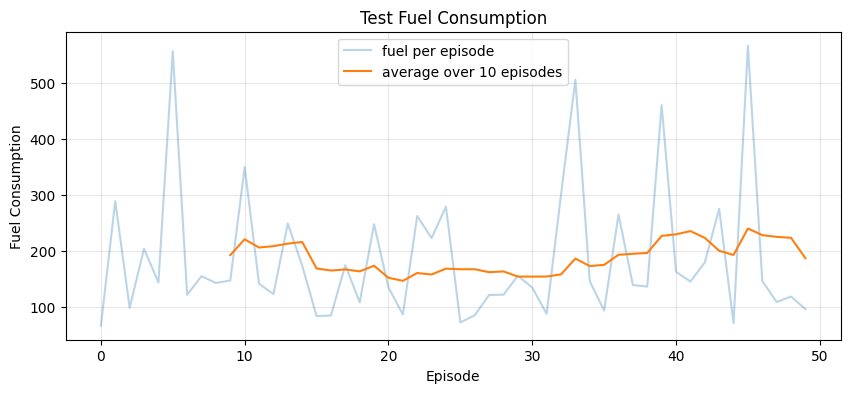

In [16]:
# Landing accuracy
print(f"\nLanded: {landed}/{episodes}")
# Landing accuracy (within goal)
print(f"Landed within goal: {landed_within_goal}/{episodes}")
# Success rate
print(f"Success rate: {landed / episodes * 100:.1f}%")
# Success rate (within goal)
print(f"Success rate (landed within goal): {landed_within_goal / episodes * 100:.1f}%")

import pandas as pd

fuel = pd.Series(fuel_consumptions)
plt.figure(figsize=(10, 4))
plt.plot(fuel, alpha=0.3, label="fuel per episode")
plt.plot(fuel.rolling(10).mean(), label="average over 10 episodes")
plt.title("Test Fuel Consumption")
plt.xlabel("Episode")
plt.ylabel("Fuel Consumption")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [17]:
print(np.mean(episode_rewards))

247.21339912240023


## Gymnasium Visualisation 

In [18]:
import gymnasium as gym
import numpy as np
from tensorflow import keras

model = keras.models.load_model("lunar_lander_dqn.keras")
env = gym.make("LunarLander-v3", render_mode="human")

episodes = 10
max_step = 1000
landed = 0
landed = 0
landed_within_goal = 0

# Statistical measures
fuel_consumptions = []
episode_rewards = []

for episode in range(episodes):
    state, _ = env.reset()
    state = np.append(state, 0.0)
    fuel_consumption = 0.0
    episode_reward = 0.0

    for step in range(1, max_step + 1):

        q_values = model.predict(
            np.expand_dims(state, axis=0),
            verbose=0)

        action = np.argmax(q_values[0])
        new_state, reward, terminated, truncated, _ = env.step(action)
        fraction_finished = (step + 1) / max_step
        state = np.append(new_state, fraction_finished)
        episode_reward += reward

        # Update fuel consumption until landed, or crashed.
        if reward < 0 or reward == (-100):
            fuel_consumption += reward * (-1)

        if terminated or truncated:
            break

    if episode_reward > 0:
        landed += 1
    if episode_reward >= 200:
        landed_within_goal += 1

    # print(f"Episode {episode + 1}: reward = {episode_reward:.1f}")
    # print(f"Fuel consumption during episode: {fuel_consumption}")
    fuel_consumptions.append(fuel_consumption)
    episode_rewards.append(episode_reward)

env.close()